# 04 — Kalman filter: educated guessing while the robot is unavailable

Our previous trackers trusted visual evidence from every frame. Unfortunately, cameras blink, detections fail, trees remain uncooperative, and measurements wobble even when the object behaves perfectly.

A **Kalman filter** combines a motion prediction with a noisy measurement. It does not see the robot and it does not recognize anything—it only maintains a careful numerical guess about **where the object is, how it is moving, and how uncertain that guess has become**.

In [2]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np

from _helpers.kalman import (
    make_motion_measurements,
    plot_filter_result,
    plot_measurement_trust,
    plot_noisy_measurements,
    plot_predict_correct_example,
    plot_sudden_turn_comparison,
    plot_uncertainty,
)
from wave_part_dual.tracking import (
    correct_position,
    filter_positions,
    initialize_constant_velocity,
    predict_constant_velocity,
)

plt.rcParams['figure.dpi'] = 75

## 1. The measurement is not reality

Imagine that a detector reports the robot's center once per frame. Those red dots are **measurements**: useful observations corrupted by pixel rounding, imperfect boxes, noise, and occasional complete absence. The green path is the truth available only because we control this small universe.

> If manufacturing unreliable evidence sounds more enjoyable than using it: [`make_motion_measurements()` implementation](./_helpers/kalman.py).

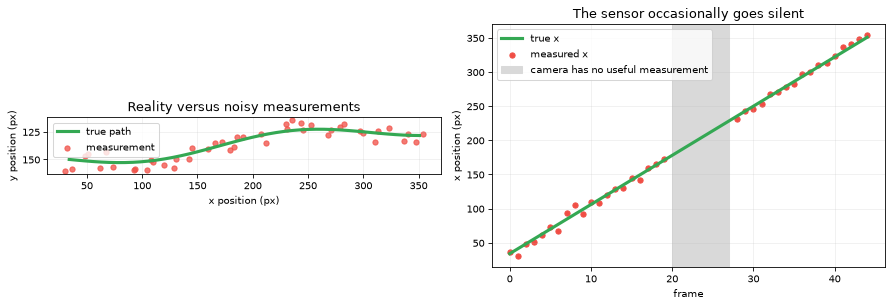

In [11]:
truth, observed, measurements, available = make_motion_measurements(
    noise_sigma=6.0,
    missing_range=(20, 28),
    seed=21,
)
plot_noisy_measurements(truth, observed, available)

## 2. State: more than just an address

The filter stores a **state**: `[x, y, vx, vy]`. Position says where the robot is; velocity says where that position is heading. This lets the filter predict the next location instead of waiting helplessly for another red dot.

Every frame has two small acts:

1. **Predict:** move the state forward using the motion model. Uncertainty grows because the robot may not obey perfectly.
2. **Correct:** compare the prediction with a measurement and settle somewhere between them. Uncertainty usually shrinks because new evidence arrived.

The exact compromise depends on which side the filter trusts more. It is less a verdict and more a very small workplace negotiation.

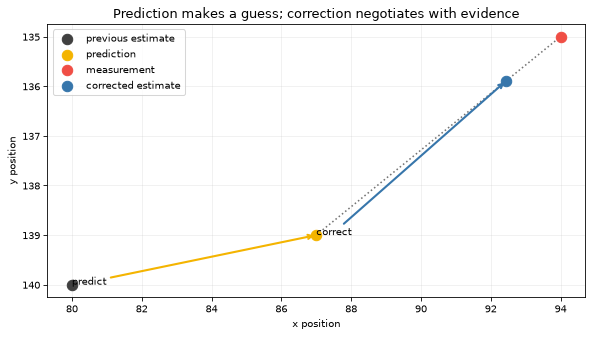

In [12]:
previous_state = initialize_constant_velocity(
    position=(80, 140),
    velocity=(7, -1),
)
predicted_state = predict_constant_velocity(previous_state, process_variance=1.0)
measurement = np.array([94, 135])
corrected_state = correct_position(
    predicted_state,
    measurement,
    measurement_variance=36.0,
)

plot_predict_correct_example(
    previous_state.mean[:2],
    predicted_state.mean[:2],
    measurement,
    corrected_state.mean[:2],
)

> **Where is the famous Kalman formula?** Inside the reusable implementation, providing comfort through its mere existence. The useful intuition here is: **prediction plus evidence, weighted by uncertainty**.

> If matrix multiplication suddenly becomes your calling: [`predict_constant_velocity()` and `correct_position()`](../../src/wave_part_dual/tracking/kalman.py).

> For a more official source with proper matrix letters and considerably less robot anxiety: [OpenCV `KalmanFilter` documentation](https://docs.opencv.org/4.x/dd/d6a/classcv_1_1KalmanFilter.html). It lists the prediction, correction, covariance, noise, and Kalman-gain equations—so everything here can now look appropriately serious.

## 3. Filtering one complete journey

We now repeat predict → correct for every frame. When a measurement is missing, correction is simply skipped: the filter continues on prediction alone and hopes the robot has not discovered teleportation.

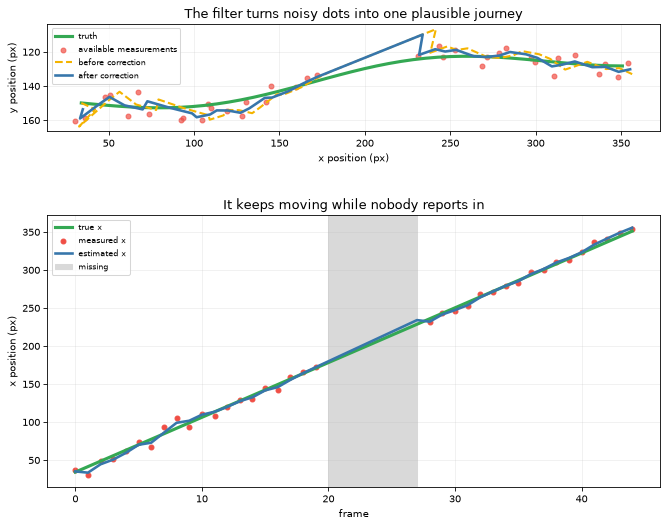

In [13]:
estimates, predictions, uncertainty = filter_positions(
    measurements,
    initial_position=truth[0],
    initial_velocity=(7.2, 0.0),
    process_variance=1.0,
    measurement_variance=6.0**2,
)
plot_filter_result(truth, observed, available, estimates, predictions)

> **Observation:** the estimated path is smoother than the red measurements. During the missing interval it keeps advancing because velocity is part of the state. That is useful prediction—not secret robot detection.

## 4. Measurement noise is a trust dial

`measurement_variance` describes how unreliable we believe the detector is. Small variance says *trust every red dot*. Large variance says *thank you for your report; management will mostly continue with its prediction*.

It is not the noise added by this cell—it is information **given to the filter** about the expected noise.

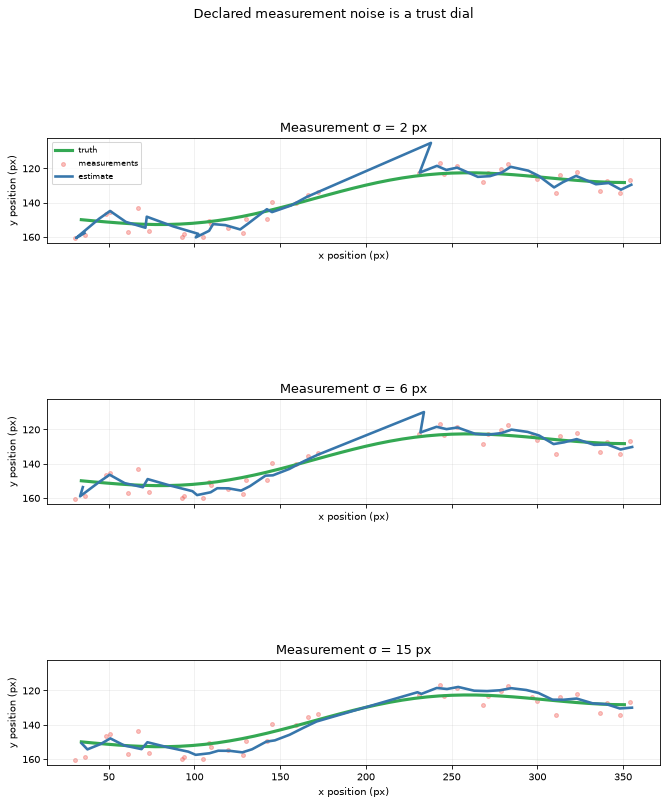

In [15]:
plot_measurement_trust(
    truth,
    observed,
    measurements,
    variances=(2.0**2, 6.0**2, 15.0**2),
)

> **Experiment:** change the real `noise_sigma` in section 1 without changing these declared values. A filter with misplaced confidence can become beautifully smooth and confidently wrong.

## 5. Uncertainty: knowing that we do not know

The filter carries a covariance matrix alongside its state. In human language, this is its estimate of how uncertain the position and velocity are—and how those errors relate.

Without measurements, the possible location spreads out. When evidence returns, the uncertainty contracts. The filter has not become sad during occlusion; it has become appropriately less certain.

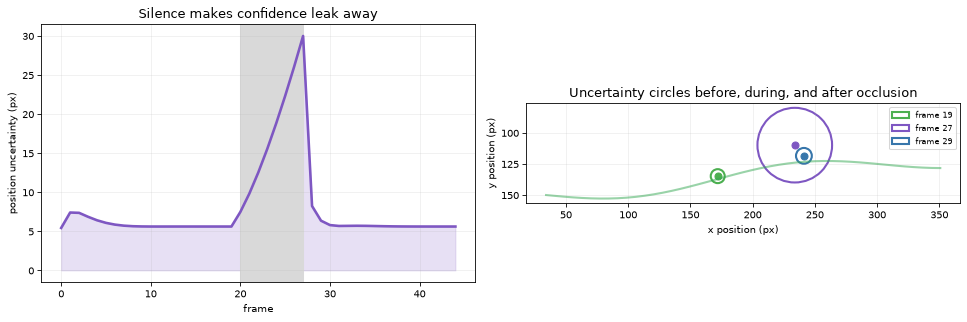

In [16]:
plot_uncertainty(truth, estimates, uncertainty, available)

## 6. The motion model is useful, not psychic

Our model assumes roughly constant velocity. Now the robot suddenly turns. `process_variance` says how much unexpected acceleration we permit:

- **Small:** smooth and confident, but slow to accept a change of plan.
- **Large:** adapts faster, but follows measurement noise more eagerly.

Every useful assumption eventually receives an invoice.

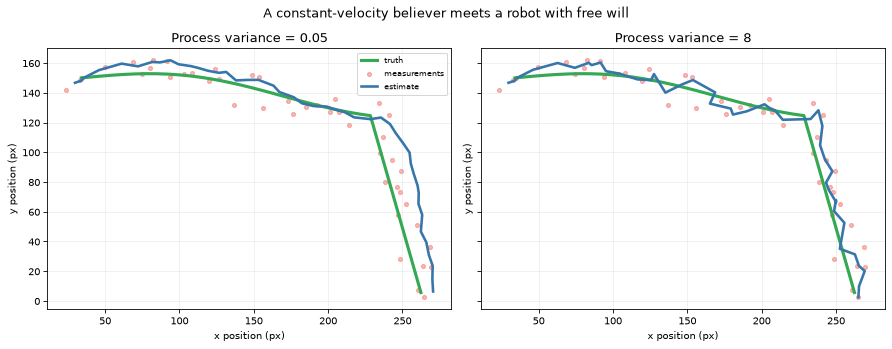

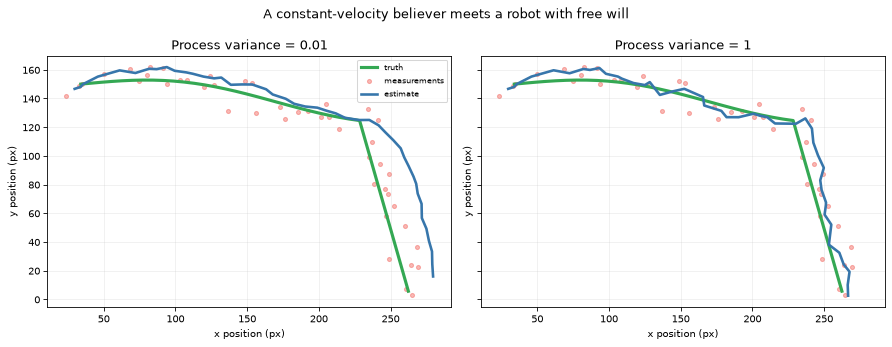

In [26]:
turn_truth, turn_observed, turn_measurements, _ = make_motion_measurements(
    noise_sigma=6.0,
    missing_range=(0, 0),
    seed=8,
    sudden_turn=True,
)
plot_sudden_turn_comparison(
    turn_truth,
    turn_observed,
    turn_measurements,
    process_variances=(0.05, 8.0),
)
plot_sudden_turn_comparison(
    turn_truth,
    turn_observed,
    turn_measurements,
    process_variances=(0.01, 1.0),
)

## 7. Where this fits in tracking

A Kalman filter does **not** replace detection, background subtraction, optical flow, or an appearance tracker. Those methods supply visual measurements. The filter smooths them, predicts the next location, and provides uncertainty when evidence disappears.

In multi-object tracking this becomes especially useful: predicted locations help decide which new detection belongs to which old track. That identity-association headache is waiting politely in the next notebook.

## Reflection

Short answers remain legal.

1. What information is stored in our filter state?
2. Why can it move during frames with no measurement?
3. What happens to uncertainty while measurements are missing?
4. What does large measurement variance tell the filter?
5. Why does a low-process-noise filter struggle after a sudden turn?

## Takeaway

A Kalman filter repeatedly predicts motion, corrects that prediction with noisy evidence, and updates how uncertain it should feel. It is valuable because tracking measurements wobble and sometimes disappear—not because the filter possesses forbidden knowledge about robots.

The result is a smoother estimate, short-term survival through missing detections, and a principled warning that a long unsupported prediction should not be trusted forever.